In [2]:
import pandas as pd
from pathlib import Path

In [3]:
# data path
DATA_PATH = Path(
    r"C:\Users\jchmo\Downloads\dataset_football_matches\big5"
)

In [4]:
# dictionary of the league names
league_names = {
    "E0": "Premier League",
    "D1": "Bundesliga",
    "I1": "Serie A",
    "SP1": "La Liga",
    "F1": "Ligue 1"
}

In [5]:
# load all the data
dataframes = []

for file in sorted(DATA_PATH.glob("*.csv")):

    # eg. E0_2122
    file_name = file.stem

    # split the name to season and league
    league_code, season_code = file_name.split("_")

    # league name
    league = league_names[league_code]

    # 2122 -> 2021/22
    start_year = 2000 + int(season_code[:2])
    end_year = 2000 + int(season_code[2:])

    season = f"{start_year}/{str(end_year)[-2:]}"

    # load CSV
    try:
        df_temp = pd.read_csv(file, encoding="utf-8-sig")
    except UnicodeDecodeError:
        df_temp = pd.read_csv(file, encoding="cp1252")

    # delete empty columns
    df_temp.columns = df_temp.columns.str.strip()

    # add info about league and season
    df_temp["Season"] = season
    df_temp["League"] = league
    df_temp["LeagueCode"] = league_code

    # save the data to dataframe
    dataframes.append(df_temp)

# concatenate all dataframes
df = pd.concat(
    dataframes,
    ignore_index=True,
    sort=False
)

In [6]:
print("\nSum of matches from season and league:")
print(df.groupby(["Season", "League"])
      .size()
      .unstack(fill_value=0)    
)


Sum of matches from season and league:
League   Bundesliga  La Liga  Ligue 1  Premier League  Serie A
Season                                                        
2021/22         306      380      380             380      380
2022/23         306      380      380             380      380
2023/24         306      380      306             380      380
2024/25         306      380      306             380      380
2025/26         306      380      306             380      380


In [7]:
print(df.columns.to_list())

['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA', 'Season', 'League', 'LeagueCode', 'BFH', 'BFD', 'BFA', '1XBH', '1XBD', '1XBA', 'BFEH', 'B

FTR                     H          D          A
League                                         
Bundesliga      44.052288  24.901961  31.045752
La Liga         45.736842  26.157895  28.105263
Ligue 1         43.444577  24.553039  32.002384
Premier League  44.157895  23.894737  31.947368
Serie A         40.368421  27.210526  32.421053


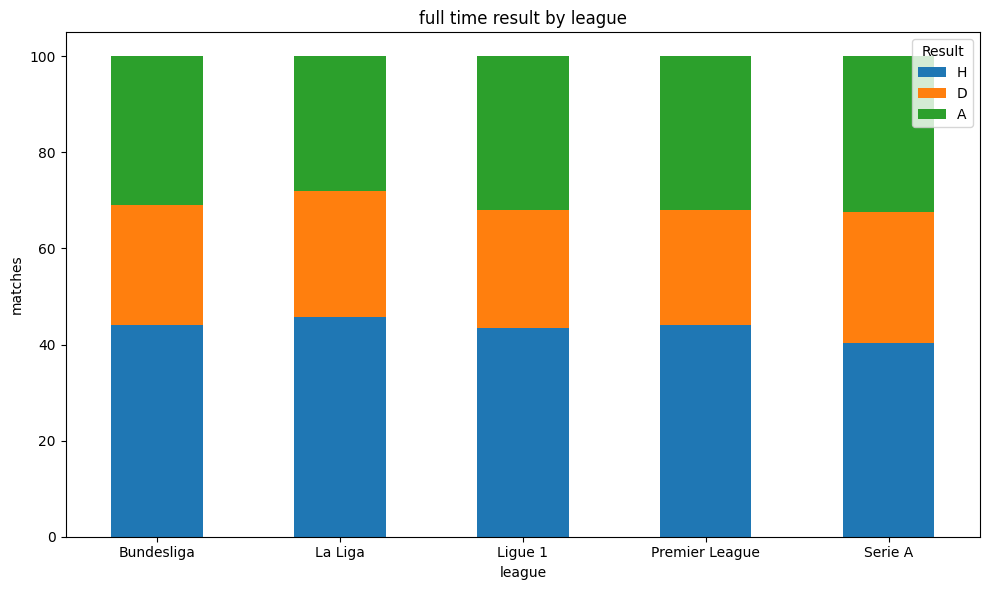

In [8]:
results_by_league = pd.crosstab(
    df["League"],
    df["FTR"],
    normalize="index",
) * 100
results_by_league = results_by_league[["H", "D", "A"]]
print(results_by_league)

import matplotlib.pyplot as plt
results_by_league.plot(kind="bar", stacked = True, figsize=(10,6))
plt.title("full time result by league")
plt.xlabel("league")
plt.ylabel("matches")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.tight_layout()
plt.show()

In [9]:
# hypothesis test - does home advantage matter?
from scipy.stats import chisquare
# choose matches without a draw
decisive_matches = df[df["FTR"].isin(["H", "A"])]

home_wins = (decisive_matches["FTR"] == "H").sum()
away_wins = (decisive_matches["FTR"] == "A").sum()

observed = [home_wins, away_wins]

expected = [sum(observed) / 2, sum(observed) / 2]

chi2, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("home wins: ", home_wins, "away wins: ", away_wins)
print("chi-square: ", chi2)
print("p-value: ", p_value)

home wins:  3878 away wins:  2769
chi-square:  185.02798254851814
p-value:  3.869805720090763e-42


League
Bundesliga        3.18
Premier League    2.93
Ligue 1           2.82
Serie A           2.61
La Liga           2.59
Name: TotalGoals, dtype: float64


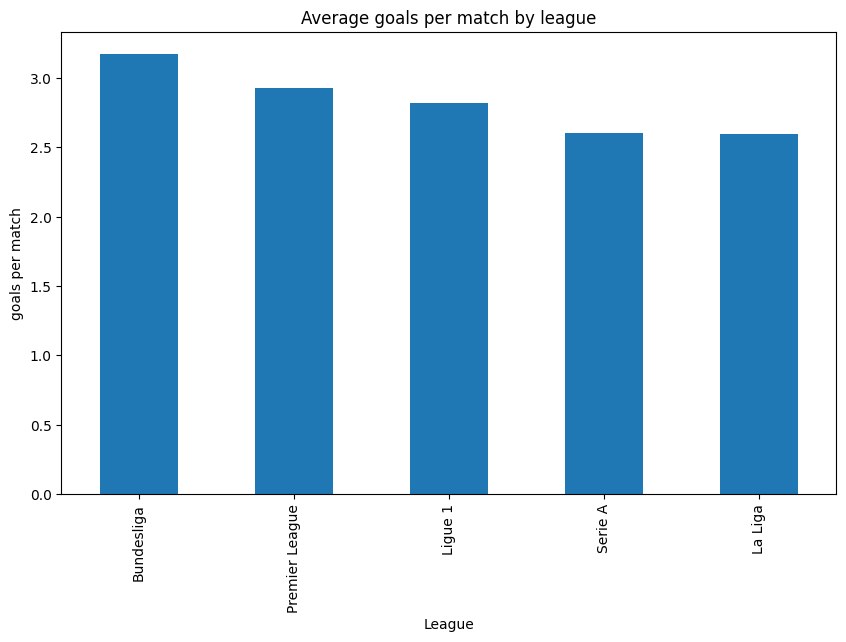

In [34]:
# are some leagues more defensive and some offensive?
# create new feature total goals
df["TotalGoals"] = df["FTHG"] + df["FTAG"]

# compute average number of goals per match by league
avg_goals = (
    df.groupby("League")["TotalGoals"]
      .mean()
      .sort_values(ascending=False)
)

print(avg_goals.round(2))

plt.figure(figsize=(10,6))
avg_goals.plot(kind = "bar")
plt.title("Average goals per match by league")
plt.xlabel("League")
plt.ylabel("goals per match")
plt.show()


In [18]:
# winning teams tend to have more shots on target?

avg_shots_on_target = (
    df.groupby("FTR")[["HST", "AST"]]
    .mean()
    .reindex(["H", "D", "A"])
)
print(avg_shots_on_target)

          HST       AST
FTR                    
H    5.891955  3.110108
D    4.370190  3.766033
A    3.703035  5.317558


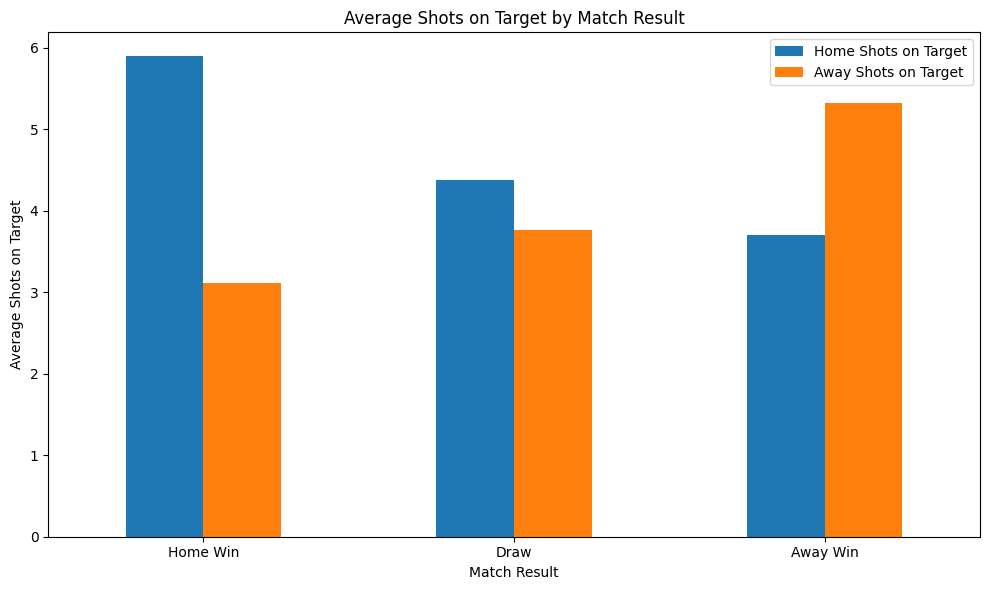

In [20]:
avg_shots_on_target.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Shots on Target by Match Result")
plt.xlabel("Match Result")
plt.ylabel("Average Shots on Target")
plt.xticks(
    range(3),
    ["Home Win", "Draw", "Away Win"],
    rotation=0
)

plt.legend(["Home Shots on Target", "Away Shots on Target"])
plt.tight_layout()
plt.show()

       HC    AC
FTR            
H    5.32  4.23
D    5.50  4.30
A    5.29  4.48


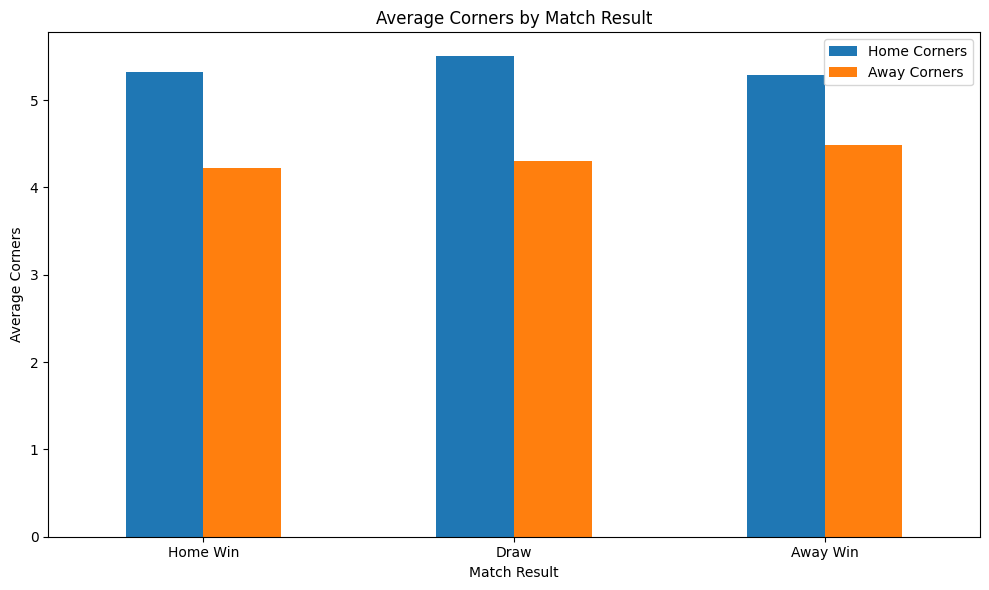

In [21]:
avg_corners = (
    df.groupby("FTR")[["HC", "AC"]]
      .mean()
      .reindex(["H", "D", "A"])
)

print(avg_corners.round(2))

avg_corners.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Corners by Match Result")
plt.xlabel("Match Result")
plt.ylabel("Average Corners")
plt.xticks(
    range(3),
    ["Home Win", "Draw", "Away Win"],
    rotation=0
)

plt.legend(["Home Corners", "Away Corners"])
plt.tight_layout()
plt.show()

League
Bundesliga        22.421844
La Liga           25.616316
Ligue 1           24.218117
Premier League    21.508421
Serie A           25.110000
Name: Total_fouls, dtype: float64


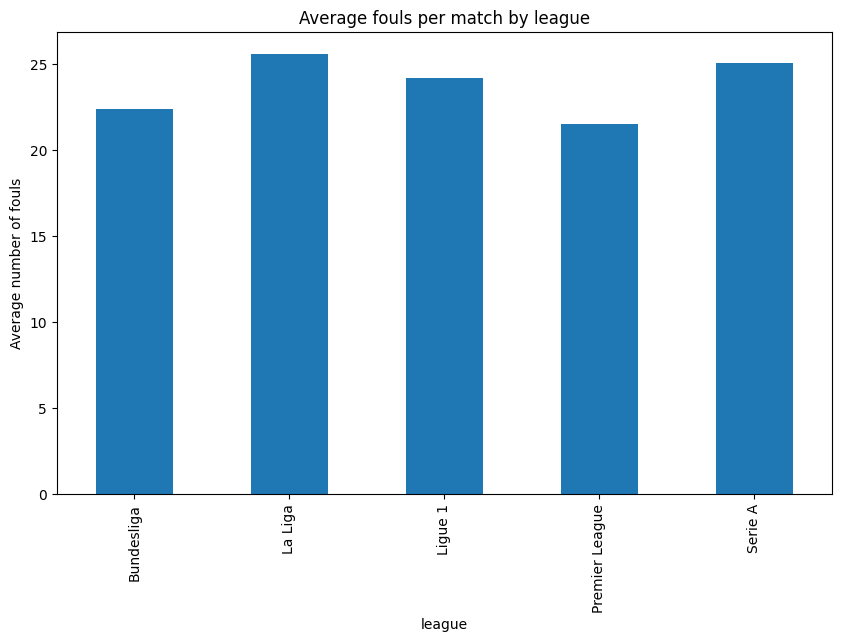

In [ ]:
# fouls vary considerably between leagues
df["Total_fouls"] = df["HF"] + df["AF"]
fouls_total = df.groupby("League")["Total_fouls"].mean()
print(fouls_total)
fouls_total.plot(kind = "bar", figsize = (10,6))
plt.title("Average fouls per match by league")
plt.xlabel("league")
plt.ylabel("Average number of fouls")
plt.show()


League
Bundesliga        4.041203
La Liga           5.023158
Ligue 1           3.984505
Premier League    3.906316
Serie A           4.404737
Name: total_cards, dtype: float64


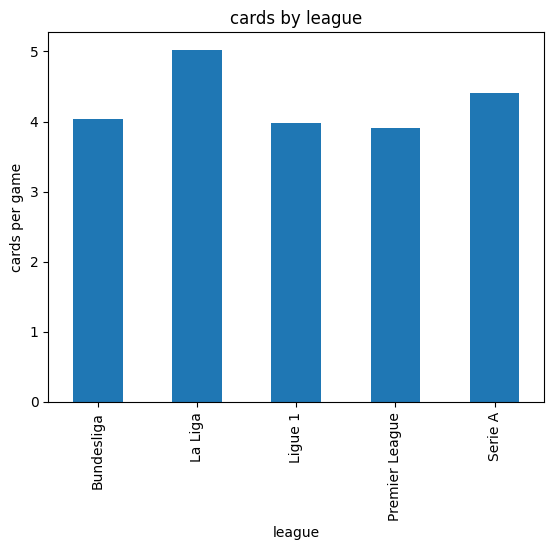

In [33]:
# cards vary considerably between leagues
df["total_cards"] = df["HY"] + df["AY"] + df["HR"] + df["AR"]
cards = df.groupby("League")["total_cards"].mean()
print(cards)
cards.plot(kind="bar")
plt.title("cards by league")
plt.xlabel("league")
plt.ylabel("cards per game")
plt.show()